# 🛢️ Historic Macro Black Swan: WTI Crude Negative Price Crash (April 20, 2020)
## Extreme Negative Outlier & Structural Break in Commodity Economics

### 1. Incident Background
On **April 20, 2020**, amid pandemic lockdowns and near-zero fuel demand, the May 2020 West Texas Intermediate (WTI) crude oil futures contract expired while the physical storage hub in Cushing, Oklahoma reached 100% tank capacity. 
* Traders facing physical delivery obligations had nowhere to store the oil.
* In a single historic trading day, spot prices plunged from **+$18.31/barrel** to **-$36.98/barrel** (producers paying buyers to haul oil away).
* This was the **first time in history an energy commodity traded at negative prices**, violating traditional log-normal price assumptions.

### 2. Target Variable ($y$)
* **`DCOILWTICO`**: Daily West Texas Intermediate (WTI) Crude Oil Spot Price ($/barrel).

### 3. Data Source
* Federal Reserve Bank of St. Louis (**FRED**) Open Data Archive.
* Series ID: `DCOILWTICO`.
* Zero credentials required, official macroeconomic benchmark.


### 📚 Academic Citations & Benchmark Lineage
* **Primary Source & Economic Study:** Federal Reserve Bank of St. Louis (FRED `DCOILWTICO`). U.S. Energy Information Administration (EIA).
* **Academic Reference:** Borenstein, S., & Kellogg, R. (2020). *"The Day WTI Went Negative: Storage Capacity Collapses and Spatial Misallocation."* *NBER Working Paper Series*.
* **BibTeX Citation:**
```bibtex
@techreport{eia2020wti,
  title={Crude Oil Prices: West Texas Intermediate (WTI) - Cushing, Oklahoma},
  author={{Federal Reserve Bank of St. Louis} and {U.S. Energy Information Administration}},
  series={FRED Economic Data},
  number={DCOILWTICO},
  year={2020}
}
```

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("Environment initialized.")

Environment initialized.


### 4. Data Ingestion from FRED

In [2]:
def fetch_fred_wti(cache_dir='data'):
    cache_path = os.path.join(cache_dir, 'wti_crude_raw.csv')
    
    if os.path.exists(cache_path):
        print(f"Loading WTI series from cache: {cache_path}")
        df = pd.read_csv(cache_path)
    else:
        print("Downloading WTI series directly from FRED...")
        url = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=DCOILWTICO'
        df = pd.read_csv(url)
        df.to_csv(cache_path, index=False)
        print(f"Downloaded and cached {len(df)} daily observations.")
        
    return df

df_wti_raw = fetch_fred_wti()
df_wti_raw.head()

Downloaded and cached 10644 daily observations.


,observation_date,DCOILWTICO
0,1986-01-02,25.56
1,1986-01-03,26.00
2,1986-01-06,26.53
3,1986-01-07,25.85
4,1986-01-08,25.87


### 5. Data Preprocessing & Structural Break Metrics

In [3]:
df_wti = df_wti_raw.copy()
df_wti['observation_date'] = pd.to_datetime(df_wti['observation_date'])
df_wti['DCOILWTICO'] = pd.to_numeric(df_wti['DCOILWTICO'], errors='coerce')
df_wti = df_wti.dropna().sort_values('observation_date').reset_index(drop=True)

# Filter to 2019-2021 window to isolate the pandemic shock
df_wti_sub = df_wti[(df_wti['observation_date'] >= '2020-01-01') & 
                    (df_wti['observation_date'] <= '2020-07-01')].copy()

# Feature engineering
df_wti_sub['price_diff_1d'] = df_wti_sub['DCOILWTICO'].diff()
df_wti_sub['rolling_std_14d'] = df_wti_sub['DCOILWTICO'].rolling(14).std()

# Baseline mean before the April collapse (Q1 2020)
baseline_price = df_wti_sub[df_wti_sub['observation_date'] < '2020-04-01']['DCOILWTICO'].mean()
df_wti_sub['z_score'] = (df_wti_sub['DCOILWTICO'] - baseline_price) / df_wti_sub['DCOILWTICO'].std()

min_row = df_wti_sub.loc[df_wti_sub['DCOILWTICO'].idxmin()]
print(f"Q1 2020 Baseline Mean Price:  ${baseline_price:.2f}/bbl")
print(f"Historic Minimum Shock Price: ${min_row['DCOILWTICO']:.2f}/bbl on {min_row['observation_date'].strftime('%Y-%m-%d')}")
print(f"1-Day Absolute Shock Drop:    ${min_row['price_diff_1d']:.2f}/bbl")
df_wti_sub[(df_wti_sub['observation_date'] >= '2020-04-15') & (df_wti_sub['observation_date'] <= '2020-04-24')]

Q1 2020 Baseline Mean Price:  $45.34/bbl
Historic Minimum Shock Price: $-36.98/bbl on 2020-04-20
1-Day Absolute Shock Drop:    $-55.29/bbl


,observation_date,DCOILWTICO,price_diff_1d,rolling_std_14d,z_score
7897,2020-04-15,19.96,-0.19,4.144967,-1.617985
7898,2020-04-16,19.82,-0.14,3.938035,-1.626912
7899,2020-04-17,18.31,-1.51,3.656702,-1.723193
7900,2020-04-20,-36.98,-55.29,16.157493,-5.248625
7901,2020-04-21,8.91,45.89,16.329473,-2.322561
7902,2020-04-22,13.64,4.73,16.336643,-2.020964
7903,2020-04-23,15.06,1.42,16.167594,-1.930422
7904,2020-04-24,15.99,0.93,15.787184,-1.871122


### 6. Timeline Visualizations of the Negative Price Crash

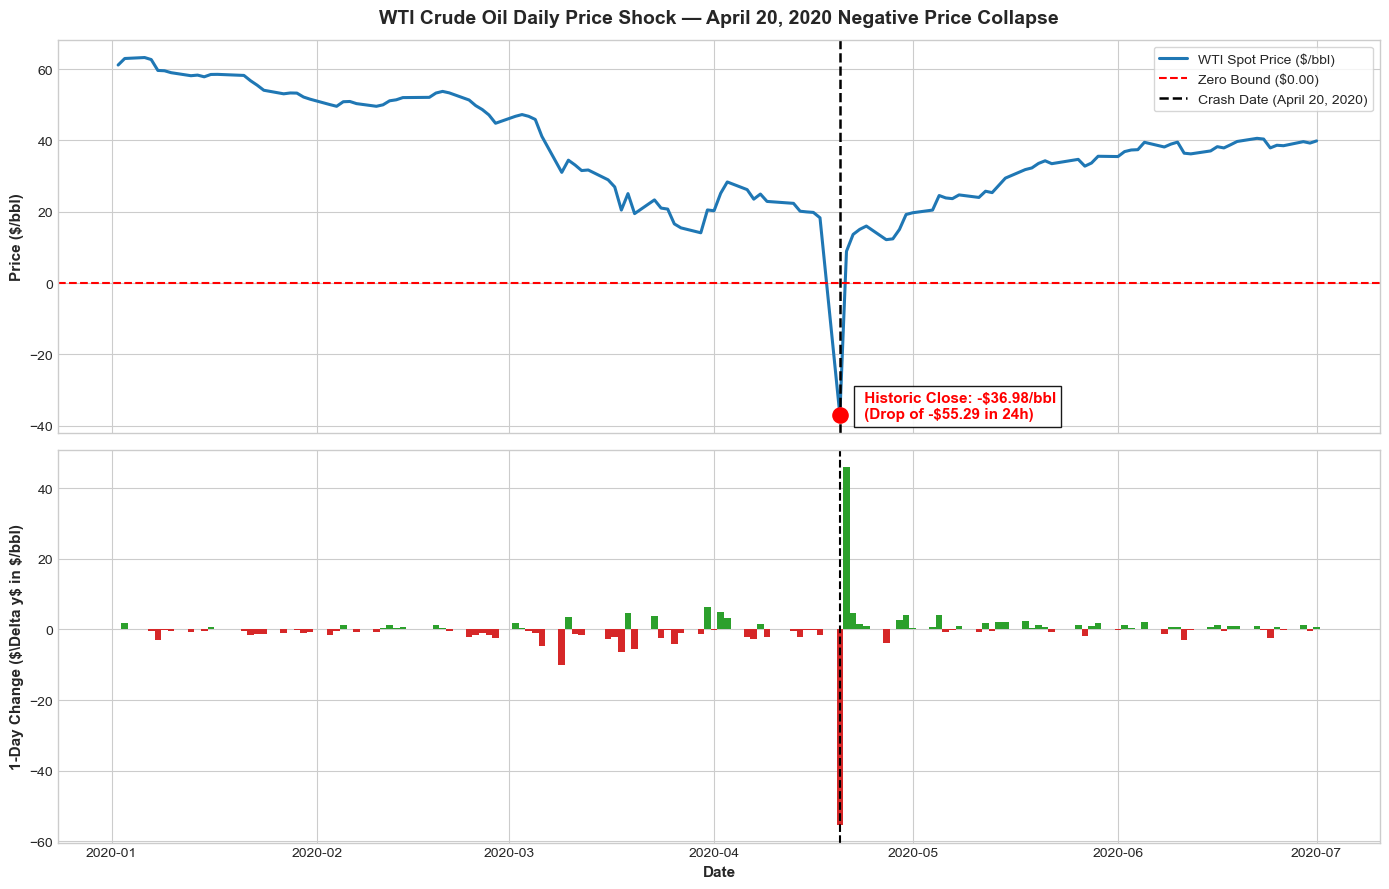

Saved clean WTI dataset to data/wti_crude_processed.csv


In [4]:
crash_date = pd.to_datetime('2020-04-20')

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# 1. Macro Price Collapse
axes[0].set_title("WTI Crude Oil Daily Price Shock — April 20, 2020 Negative Price Collapse", 
                  fontsize=14, fontweight='bold', pad=12)
axes[0].plot(df_wti_sub['observation_date'], df_wti_sub['DCOILWTICO'], color='#1f77b4', lw=2.2, label='WTI Spot Price ($/bbl)')
axes[0].axhline(0, color='red', ls='--', lw=1.5, label='Zero Bound ($0.00)')
axes[0].axvline(crash_date, color='black', ls='--', lw=1.8, label='Crash Date (April 20, 2020)')
axes[0].scatter([crash_date], [-36.98], color='red', s=120, zorder=5)
axes[0].text(crash_date + pd.Timedelta(days=3), -38, " Historic Close: -$36.98/bbl\n (Drop of -$55.29 in 24h)", 
             fontsize=11, fontweight='bold', color='red', bbox=dict(facecolor='white', alpha=0.9))
axes[0].set_ylabel("Price ($/bbl)", fontsize=11, fontweight='bold')
axes[0].legend(loc='upper right', frameon=True)

# 2. Daily Price Change (Delta y)
axes[1].bar(df_wti_sub['observation_date'], df_wti_sub['price_diff_1d'], 
            color=np.where(df_wti_sub['price_diff_1d'] >= 0, '#2ca02c', '#d62728'), width=1.0)
axes[1].axvline(crash_date, color='black', ls='--', lw=1.5)
axes[1].set_ylabel("1-Day Change ($\\Delta y$ in $/bbl)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Date", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig('data/wti_negative_crash_timeline.png', dpi=300)
plt.show()

# Export clean dataset
df_wti_sub.to_csv('data/wti_crude_processed.csv', index=False)
print("Saved clean WTI dataset to data/wti_crude_processed.csv")